# Spike #11 — Google Trends distingue-t-il une tendance durable d'un buzz avant le pic ?

**Question** : les courbes Google Trends de la pistache et du matcha (durables) se distinguent-elles de celle du Dalgona coffee (buzz) avant leur pic ?
**Méthode** : séries mensuelles 2019-2025 sur 5 pays (FR, US, JP, KR, AE), données figées 3 mois avant chaque pic, règle simple sur la pente, la tenue et les pays touchés (score v1 du ticket #25).
**Seuil** : 3 cas sur 3 bien classés avant le pic.

Données : exports Google Trends du 12/11/2026 (`raw/google_trends/`, manifeste `metadata/search_manifest_google_trends.csv`), requêtes du dictionnaire `metadata/dictionnaire_requetes.csv` v1, toutes catégories, recherche Web.
Seuils : `config/seuils_score_v1.json`, écrits avant ce test.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
import pandas as pd, matplotlib.pyplot as plt
from sillage_score import charger_google_trends, lire_export_google_trends, score, SEUILS
pd.set_option("display.width", 160)
CAS = {"matcha": "durable", "pistachio": "durable", "dalgona_coffee": "buzz"}
series = {t: charger_google_trends(t) for t in CAS}
{t: {p: len(s) for p, s in d.items()} for t, d in series.items()}

{'matcha': {'FR': 94, 'US': 94, 'JP': 94, 'KR': 94, 'AE': 94},
 'pistachio': {'FR': 94, 'US': 94, 'JP': 94, 'KR': 94, 'AE': 94},
 'dalgona_coffee': {'FR': 94, 'US': 94, 'JP': 94, 'KR': 94}}

Le fichier Dalgona × Émirats est vide : Google Trends ne renvoie aucune donnée pour la requête arabe. La zone est absente, ce n'est pas un zéro.

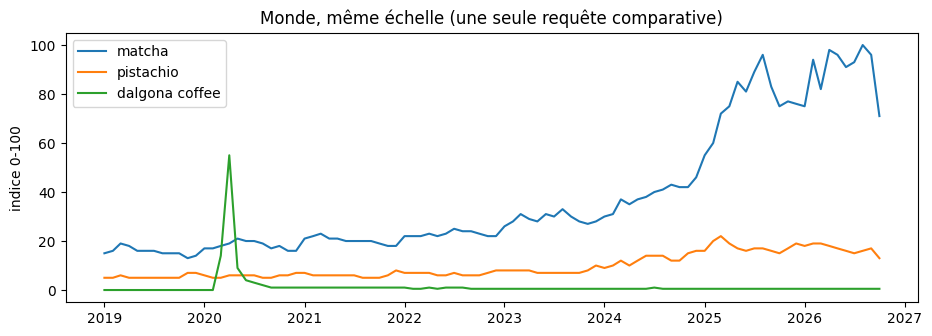

In [2]:
monde = lire_export_google_trends("raw/google_trends/gt__comparaison_monde__WORLD__2019-2026__monthly__001.csv")
fig, ax = plt.subplots(figsize=(11, 3.5))
for nom, s in monde.items():
    ax.plot(s.index.to_timestamp(), s.values, label=nom.split(":")[0])
ax.set_title("Monde, même échelle (une seule requête comparative)"); ax.set_ylabel("indice 0-100"); ax.legend(); plt.show()

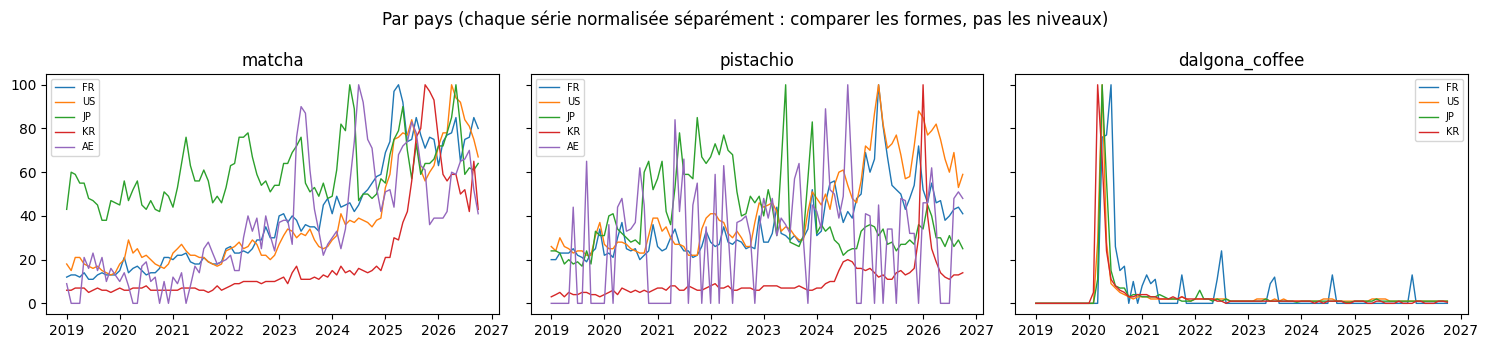

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (t, d) in zip(axes, series.items()):
    for p, s in d.items():
        ax.plot(s.index.to_timestamp(), s.values, label=p, lw=1)
    ax.set_title(t); ax.legend(fontsize=7)
plt.suptitle("Par pays (chaque série normalisée séparément : comparer les formes, pas les niveaux)"); plt.tight_layout(); plt.show()

## 1. Pics 2019-2025 et dates figées (pic − 3 mois)
Le pic est lu sur la série mondiale comparative, restreinte à 2019-2025 comme demandé dans le ticket.

In [4]:
lignes = []
for nom, s in monde.items():
    t = {"matcha": "matcha", "pistachio": "pistachio", "dalgona coffee": "dalgona_coffee"}[nom.split(":")[0]]
    s25 = s[(s.index >= pd.Period("2019-01", "M")) & (s.index <= pd.Period("2025-12", "M"))]
    pic = s25.idxmax()
    lignes.append({"cas": t, "label_attendu": CAS[t], "mois_pic": str(pic), "date_figee": str(pic - 3)})
pics = pd.DataFrame(lignes); pics

,cas,label_attendu,mois_pic,date_figee
0,matcha,durable,2025-08,2025-05
1,pistachio,durable,2025-03,2024-12
2,dalgona_coffee,buzz,2020-04,2020-01


## 2. Score v1 à la date figée (aucune donnée postérieure utilisée)
Traduction du verdict : `suivre` = durable ; `ignorer` = buzz / pas de tendance ; `surveiller` = indécis (compté comme non classé).

In [5]:
def classe(v):
    return {"suivre": "durable", "ignorer": "buzz"}.get(v, "indécis")
res = []
for r in pics.itertuples():
    sc = score(series[r.cas], r.date_figee, nom_affiche="masqué")
    res.append({"cas": r.cas, "date_figee": r.date_figee, "score": sc["score"], "duree": sc["composantes"]["duree"],
                "geographie": sc["composantes"]["geographie"], "zones_signal": ",".join(sc["zones_avec_signal"]),
                "verdict": sc["verdict_propose"], "classe": classe(sc["verdict_propose"]), "attendu": r.label_attendu})
res = pd.DataFrame(res); res["correct"] = res.classe == res.attendu
res

,cas,date_figee,score,duree,geographie,zones_signal,verdict,classe,attendu,correct
0,matcha,2025-05,82.0,83.3,80.0,"AE,FR,JP,KR,US",suivre,durable,durable,True
1,pistachio,2024-12,74.0,83.3,60.0,"AE,FR,JP,KR,US",suivre,durable,durable,True
2,dalgona_coffee,2020-01,0.0,0.0,0.0,,ignorer,buzz,buzz,True


In [6]:
print(f"Cas bien classés avant le pic : {res.correct.sum()} / {len(res)} (seuil du ticket : 3/3)")

Cas bien classés avant le pic : 3 / 3 (seuil du ticket : 3/3)


## 3. Robustesse : le score mois par mois
Le verdict ne doit pas dépendre d'une date choisie au mois près. On recalcule le score chaque mois, toujours sans regarder le futur.

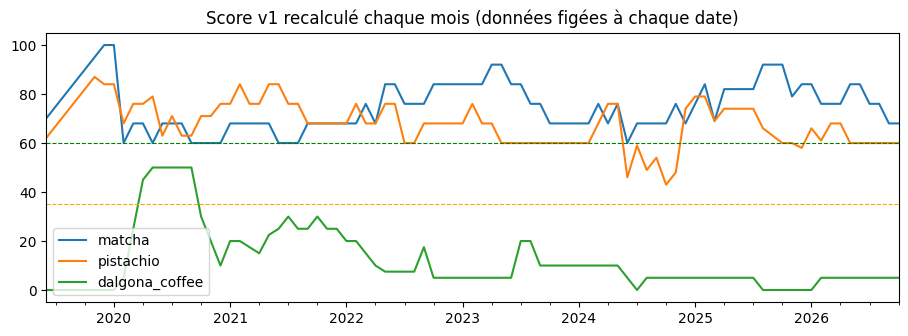

,matcha,pistachio,dalgona_coffee
2020-01-01,100.0,84.0,0.0
2020-02-01,60.0,68.0,5.0
2020-03-01,68.0,76.0,25.0
2020-04-01,68.0,76.0,45.0
2020-05-01,60.0,79.0,50.0
2020-06-01,68.0,63.0,50.0
2020-07-01,68.0,71.0,50.0
2020-08-01,68.0,63.0,50.0


In [7]:
mois = pd.period_range("2019-06", "2026-10", freq="M")
traj = pd.DataFrame({t: [score(series[t], str(m))["score"] for m in mois] for t in CAS}, index=mois.to_timestamp())
ax = traj.plot(figsize=(11, 3.5), title="Score v1 recalculé chaque mois (données figées à chaque date)")
ax.axhline(SEUILS["verdict"]["suivre"], ls="--", c="g", lw=0.8); ax.axhline(SEUILS["verdict"]["surveiller"], ls="--", c="orange", lw=0.8)
plt.show()
traj.loc["2020-01":"2020-08"].round(1)

In [8]:
# Marge par rapport au seuil « suivre » aux dates figées : un score collé au seuil est fragile
res.assign(marge_vs_suivre=res.score - SEUILS["verdict"]["suivre"])[["cas", "score", "marge_vs_suivre", "verdict"]]

,cas,score,marge_vs_suivre,verdict
0,matcha,82.0,22.0,suivre
1,pistachio,74.0,14.0,suivre
2,dalgona_coffee,0.0,-60.0,ignorer


## 4. Propagation entre pays (proposition cross-market du ticket #25)
Mois d'apparition par pays et décalage. **Un décalage n'est pas une causalité.**

In [9]:
for t in CAS:
    sc = score(series[t], "2026-10")
    print(t, [(p["zone"], p["mois"], p["decalage_mois"]) for p in sc["propagation"]])

matcha [('AE', '2019-07', 0), ('KR', '2025-03', 68), ('US', '2025-04', 69)]
pistachio [('AE', '2019-09', 0), ('JP', '2020-11', 14), ('KR', '2024-06', 57), ('FR', '2025-03', 66)]
dalgona_coffee [('JP', '2020-03', 0), ('KR', '2020-03', 0), ('US', '2020-03', 0), ('FR', '2020-04', 1)]


## Décision
_Décision rédigée après exécution._